---
title: "Chapter 5: Polynomial and Rational Functions"
subtitle: Notes drawn from OpenStax *Algebra and Trigonometry 2e* (§5.1–5.8) and *Precalculus 2e*
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
    "legend.frameon": True, "legend.facecolor": "#fcfcfb", "legend.edgecolor": "none", "legend.framealpha": 0.92, "figure.dpi": 110,
})

def setup(ax, xlim, ylim, title=None, ticks=1):
    """Axes through the origin, light grid, square units."""
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    for s in ("left", "bottom"):
        ax.spines[s].set_position("zero"); ax.spines[s].set_color(INK2)
    for s in ("right", "top"):
        ax.spines[s].set_visible(False)
    ax.set_xticks(np.arange(np.ceil(xlim[0]), xlim[1] + 0.01, ticks))
    ax.set_yticks(np.arange(np.ceil(ylim[0]), ylim[1] + 0.01, ticks))
    ax.tick_params(labelsize=8)
    ax.grid(color="#e6e5e0", linewidth=0.6); ax.set_axisbelow(True)
    ax.set_aspect("equal")
    if title: ax.set_title(title)

def dot(ax, x, y, filled=True, color=BLUE):
    ax.plot(x, y, "o", ms=7, color=color,
            mfc=color if filled else "#fcfcfb", mew=2, zorder=5)

In [2]:
def data_axes(ax, title=None, xlabel=None, ylabel=None):
    for s in ("right", "top"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color(INK2)
    ax.grid(color="#e6e5e0", linewidth=0.6); ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)
    if title: ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel, fontsize=9, color=INK2)
    if ylabel: ax.set_ylabel(ylabel, fontsize=9, color=INK2)

def clip(y, lim):
    """Break a curve where it runs off the plot (asymptotes)."""
    y = np.asarray(y, dtype=float).copy(); y[np.abs(y) > lim] = np.nan; return y

(sec-5-1)=
## 5.1 Quadratic Functions

### Two forms

| Form | Equation | Reads off directly |
|---|---|---|
| General | $f(x) = ax^2 + bx + c$, $a \ne 0$ | $y$-intercept $c$; opens up if $a > 0$, down if $a < 0$ |
| Standard (vertex) | $f(x) = a(x - h)^2 + k$ | vertex $(h, k)$; axis of symmetry $x = h$ |

From general form, the vertex is

$$
h = -\frac{b}{2a}, \qquad k = f(h).
$$

- If $a > 0$, $k$ is the **minimum** value and the range is $[k, \infty)$. If $a < 0$, $k$ is the **maximum** and the range is $(-\infty, k]$. The domain is always $\mathbb{R}$.
- The $x$-intercepts come from $f(x) = 0$: factor, or use the quadratic formula $x = \dfrac{-b \pm \sqrt{b^2 - 4ac}}{2a}$. The discriminant $b^2 - 4ac$ tells you whether there are 2, 1, or 0 real intercepts.

**Worked example.** $f(x) = 2x^2 - 8x + 3$, two ways.

By completing the square: factor $a$ out of the $x$ terms first, then add and subtract the square of half the $x$-coefficient *inside* the parentheses.

$$
\begin{aligned}
f(x) &= 2(x^2 - 4x) + 3 \\
&= 2(x^2 - 4x + 4 - 4) + 3 \\
&= 2(x - 2)^2 - 8 + 3 = 2(x - 2)^2 - 5
\end{aligned}
$$

The $-4$ inside the parentheses comes out as $2 \cdot (-4) = -8$, because it is still multiplied by $a = 2$. By the vertex formula instead:

$$
\begin{aligned}
h &= -\frac{-8}{2 \cdot 2} = 2, \qquad k = f(2) = 8 - 16 + 3 = -5 \\
0 = 2(x - 2)^2 - 5 &\implies (x - 2)^2 = \tfrac{5}{2} \implies x = 2 \pm \sqrt{\tfrac{5}{2}} \approx 0.42,\ 3.58
\end{aligned}
$$

Minimum $-5$ at $x = 2$; range $[-5, \infty)$; $y$-intercept $(0, 3)$.

### The discriminant

| $b^2 - 4ac$ | Real zeros | Graph |
|---|---|---|
| $> 0$ | two | crosses the $x$-axis twice |
| $= 0$ | one (a double zero) | vertex sits on the $x$-axis |
| $< 0$ | none (two complex zeros) | never touches the $x$-axis |

### Optimization

When a quantity is a quadratic function of a choice variable, the best choice is at the vertex.

**Worked example.** 80 m of fence encloses a rectangle along a river (no fence on the river side). With $W$ the two sides perpendicular to the river, the long side is $80 - 2W$:

$$
A(W) = W(80 - 2W) = -2W^2 + 80W, \qquad W = -\frac{80}{2(-2)} = 20, \qquad A(20) = 800 \text{ m}^2
$$

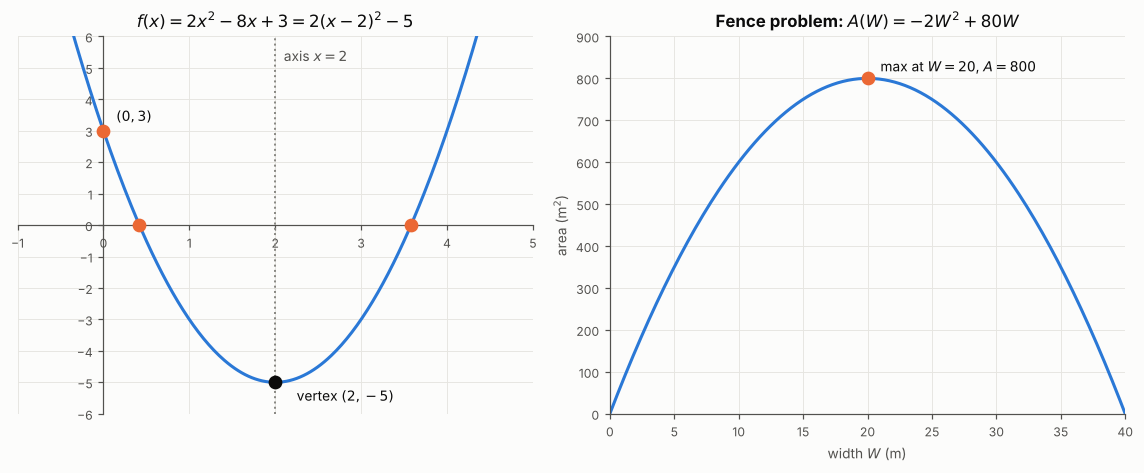

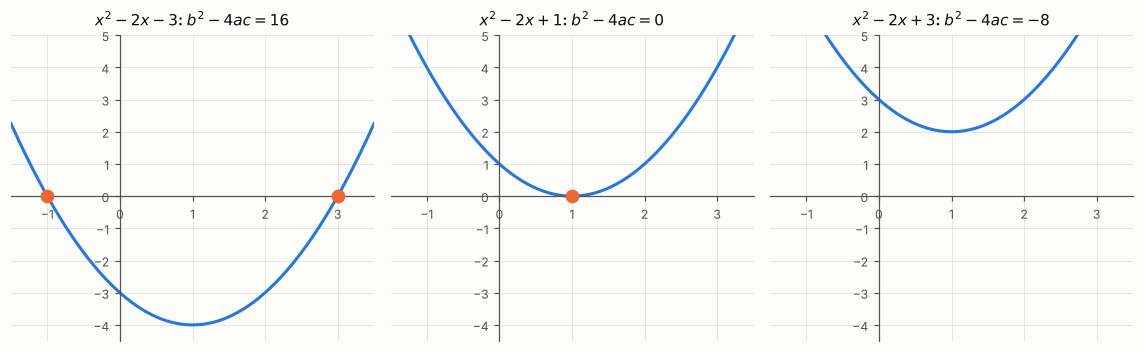

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
ax = axes[0]; setup(ax, (-1, 5), (-6, 6), "$f(x) = 2x^2 - 8x + 3 = 2(x - 2)^2 - 5$"); ax.set_aspect("auto")
x = np.linspace(-1, 5, 300); ax.plot(x, 2*x**2 - 8*x + 3, color=BLUE)
ax.axvline(2, color=GRAY, ls=":", lw=1.3)
r1, r2 = 2 - np.sqrt(2.5), 2 + np.sqrt(2.5)
dot(ax, 2, -5, color=INK); dot(ax, 0, 3, color=ORANGE); dot(ax, r1, 0, color=ORANGE); dot(ax, r2, 0, color=ORANGE)
ax.text(2.25, -5.6, "vertex $(2, -5)$", fontsize=9)
ax.text(2.1, 5.2, "axis $x = 2$", fontsize=9, color=INK2)
ax.text(0.15, 3.3, "$(0, 3)$", fontsize=9)

ax = axes[1]; data_axes(ax, "Fence problem: $A(W) = -2W^2 + 80W$", "width $W$ (m)", "area (m$^2$)")
W = np.linspace(0, 40, 200); ax.plot(W, -2*W**2 + 80*W, color=BLUE)
dot(ax, 20, 800, color=ORANGE); ax.text(21, 815, "max at $W = 20$, $A = 800$", fontsize=9)
ax.set_xlim(0, 40); ax.set_ylim(0, 900)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.3))
x = np.linspace(-1.5, 3.5, 200)
for ax, (c, t) in zip(axes, [(-3, "$x^2 - 2x - 3$: $b^2 - 4ac = 16$"), (1, "$x^2 - 2x + 1$: $b^2 - 4ac = 0$"),
                             (3, "$x^2 - 2x + 3$: $b^2 - 4ac = -8$")]):
    setup(ax, (-1.5, 3.5), (-4.5, 5), t); ax.set_aspect("auto"); ax.title.set_fontsize(10)
    ax.plot(x, x**2 - 2*x + c, color=BLUE)
    if c == -3: dot(ax, -1, 0, color=ORANGE); dot(ax, 3, 0, color=ORANGE)
    if c == 1: dot(ax, 1, 0, color=ORANGE)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Sign of $h$: $a(x - h)^2 + k$ with $(x + 3)^2$ means $h = -3$.
- Forgetting $k = f(h)$; the vertex needs both coordinates.
- Completing the square with $a \ne 1$ without factoring $a$ out of the $x$ terms first.
- Answering an optimization question with the vertex's $x$ when it asks for the maximum value (or the reverse).
:::

:::{tip} Where this shows up
The normal log-likelihood in $\mu$ is a downward parabola, $-\dfrac{n}{2\sigma^2}(\mu - \bar{x})^2 + \text{const}$, so the MLE is its vertex, $\hat\mu = \bar{x}$. Completing the square is the key algebra step in deriving the normal posterior in Hoff Ch. 5.
:::

(sec-5-2)=
## 5.2 Power Functions and Polynomial Functions

### Definitions

- **Power function:** $f(x) = kx^p$ for constants $k$ and $p$.
- **Polynomial function:** $f(x) = a_n x^n + \dots + a_1 x + a_0$, with $n$ a nonnegative integer. **Degree** $n$, **leading term** $a_n x^n$, **leading coefficient** $a_n$.

### End behavior

As $x \to \pm\infty$, a polynomial behaves like its **leading term** alone.

| | $a_n > 0$ | $a_n < 0$ |
|---|---|---|
| $n$ even | $x \to \pm\infty$: $f(x) \to \infty$ (both ends up) | $f(x) \to -\infty$ (both ends down) |
| $n$ odd | $x \to -\infty$: $f \to -\infty$; $x \to \infty$: $f \to \infty$ (down–up) | $x \to -\infty$: $f \to \infty$; $x \to \infty$: $f \to -\infty$ (up–down) |

A polynomial of degree $n$ has **at most $n$ real zeros** and **at most $n - 1$ turning points**.

**Worked example.** $f(x) = -x(x - 4)(x + 1)^2$. Multiplying out the leading terms of each factor gives $-x \cdot x \cdot x^2 = -x^4$: degree 4, leading coefficient $-1$, so both ends go down. There are at most 4 real zeros (here $0, 4, -1$) and at most 3 turning points. You don't have to expand to find the leading term.

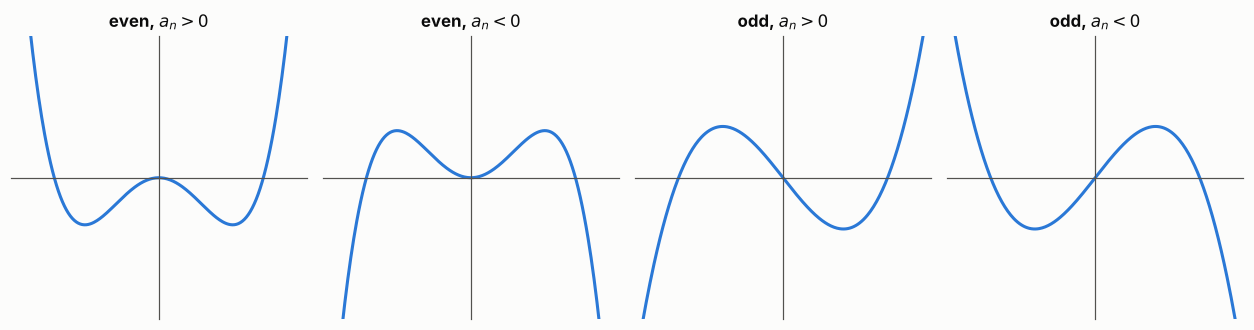

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.1))
x = np.linspace(-2, 2, 300)
cases = [("even, $a_n > 0$", x**4 - 2*x**2), ("even, $a_n < 0$", -(x**4 - 2*x**2)),
         ("odd, $a_n > 0$", x**3 - 2*x), ("odd, $a_n < 0$", -(x**3 - 2*x))]
for ax, (t, y) in zip(axes, cases):
    setup(ax, (-2, 2), (-3, 3), t); ax.set_aspect("auto")
    ax.plot(x, clip(y, 3.2), color=BLUE)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Taking the "leading term" as whatever is written first. Find the **highest power**; in $3 + 2x - 5x^3$ it is $-5x^3$.
- Calling $x^{-2}$, $\sqrt{x}$, or $2^x$ a polynomial term. Only nonnegative integer powers count.
- Thinking degree $n$ means exactly $n$ turning points. It is at most $n - 1$.
:::

:::{tip} Where this shows up
Polynomial regression (adding $x^2$, $x^3$ terms) is the simplest way to bend a fitted curve, and end behavior is why it extrapolates so badly. Power functions $y = kx^p$ are the allometric and species–area laws of §5.8.
:::

(sec-5-3)=
## 5.3 Graphs of Polynomial Functions

### Zeros and multiplicity

If $(x - c)^m$ is a factor and $m$ is as large as possible, $c$ is a zero of **multiplicity** $m$.

| Multiplicity | Behavior at $x = c$ |
|---|---|
| 1 | crosses, nearly straight |
| even (2, 4, …) | touches and turns back (bounces) |
| odd $\ge 3$ | crosses, flattening out as it passes |

The multiplicities add up to the degree (counting complex zeros, §5.5).

### Graphing a factored polynomial

1. Zeros and multiplicities (cross or bounce).
2. End behavior from the leading term.
3. $y$-intercept, $f(0)$.
4. Connect smoothly, using at most $n - 1$ turning points.

**Worked example.** $f(x) = -(x + 2)(x - 1)^2(x - 3)$: degree 4, leading term $-x^4$, so both ends down. Zeros: $-2$ (cross), $1$ (bounce), $3$ (cross). $f(0) = -(2)(1)(-3) = 6$.

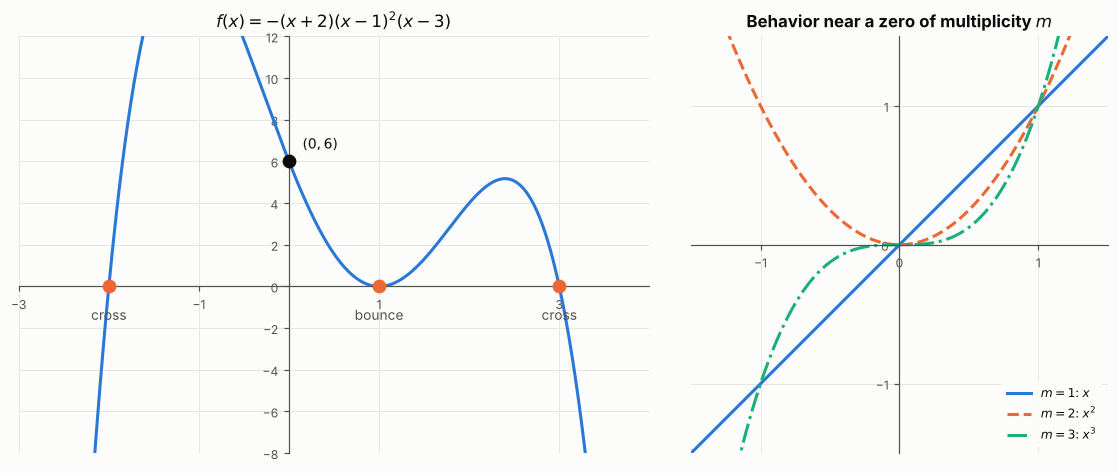

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]; setup(ax, (-3, 4), (-8, 12), r"$f(x) = -(x + 2)(x - 1)^2(x - 3)$", ticks=2)
ax.set_aspect("auto")
x = np.linspace(-3, 4, 400); y = -(x + 2)*(x - 1)**2*(x - 3)
ax.plot(x, clip(y, 13), color=BLUE)
for c, lab in [(-2, "cross"), (1, "bounce"), (3, "cross")]:
    dot(ax, c, 0, color=ORANGE); ax.text(c, -1.6, lab, ha="center", fontsize=9, color=INK2)
dot(ax, 0, 6, color=INK); ax.text(0.15, 6.6, "$(0, 6)$", fontsize=9)

ax = axes[1]; setup(ax, (-1.5, 1.5), (-1.5, 1.5), "Behavior near a zero of multiplicity $m$", ticks=1)
x = np.linspace(-1.5, 1.5, 300)
ax.plot(x, x, color=BLUE, label="$m = 1$: $x$")
ax.plot(x, x**2, color=ORANGE, ls="--", label="$m = 2$: $x^2$")
ax.plot(x, x**3, color=AQUA, ls="-.", label="$m = 3$: $x^3$")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### Intermediate Value Theorem

If $f$ is a polynomial and $f(a)$ and $f(b)$ have opposite signs, then $f(c) = 0$ for at least one $c$ between $a$ and $b$.

For $f(x) = x^3 - 2x - 5$: $f(2) = -1 < 0$ and $f(3) = 16 > 0$, so there is a zero in $(2, 3)$.

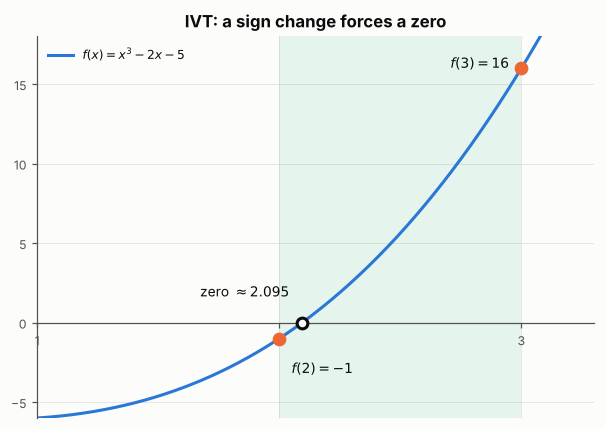

In [6]:
fig, ax = plt.subplots(figsize=(5.6, 4.0))
setup(ax, (1, 3.3), (-6, 18), "IVT: a sign change forces a zero", ticks=1); ax.set_aspect("auto")
ax.set_yticks(np.arange(-5, 18, 5))
ax.spines["left"].set_position(("axes", 0))
x = np.linspace(1, 3.3, 300); ax.plot(x, x**3 - 2*x - 5, color=BLUE, label="$f(x) = x^3 - 2x - 5$")
ax.axvspan(2, 3, color=AQUA, alpha=0.10, lw=0)
dot(ax, 2, -1, color=ORANGE); dot(ax, 3, 16, color=ORANGE)
ax.text(2.05, -3.2, "$f(2) = -1$", fontsize=9); ax.text(2.95, 16, "$f(3) = 16$", ha="right", fontsize=9)
z = np.roots([1, 0, -2, -5]); z = z[np.isreal(z)].real[0]
dot(ax, z, 0, filled=False, color=INK); ax.text(z - 0.05, 1.6, f"zero $\\approx {z:.3f}$", ha="right", fontsize=9)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### Writing a formula from a graph

Read the zeros and their behavior, write $f(x) = a(x - c_1)^{m_1}(x - c_2)^{m_2}\cdots$, then use one more point (usually the $y$-intercept) to solve for $a$.

**Worked example.** A degree-3 graph crosses at $x = -3$, bounces at $x = 1$, and passes through $(0, -6)$.

$$
\begin{aligned}
f(x) &= a(x + 3)(x - 1)^2 \\
f(0) &= a(3)(1) = 3a = -6 \implies a = -2 \\
f(x) &= -2(x + 3)(x - 1)^2
\end{aligned}
$$

Check: the leading term is $-2x^3$, so the graph should rise on the left and fall on the right. If that doesn't match the picture, the sign of $a$ is wrong.

:::{admonition} Common mistakes
:class: warning
- Reading the sign of a zero from the factor: $(x + 2)$ gives the zero $x = -2$.
- Forgetting the stretch factor $a$ when writing a formula from a graph. Zeros alone fix the shape, not the height.
- Using IVT in reverse: if $f(a)$ and $f(b)$ have the **same** sign, there could still be zeros in between (e.g., a bounce, or two crossings).
:::

:::{important} The book underplays this
The IVT is stated here only for polynomials, but it holds for any **continuous** function. It is one of the core theorems in Stewart, it's how bisection root-finding works, and its proof is a standard first exercise in real analysis.
:::

:::{tip} Where this shows up
When a likelihood equation has no closed-form solution, numerical root-finders (bisection, Newton's method) locate the zero of the score function. Bisection is the IVT turned into an algorithm.
:::

(sec-5-4)=
## 5.4 Dividing Polynomials

### The Division Algorithm

For polynomials $f$ (dividend) and $d \ne 0$ (divisor), there are unique $q$ (quotient) and $r$ (remainder) with

$$
f(x) = d(x)\,q(x) + r(x), \qquad r = 0 \ \text{ or } \ \deg r < \deg d.
$$

Equivalently, $\dfrac{f(x)}{d(x)} = q(x) + \dfrac{r(x)}{d(x)}$.

- **Long division** works for any divisor. Divide leading terms, multiply back, subtract, repeat.
- **Synthetic division** is a shortcut for divisors of the form $x - k$ only. Write $k$, the coefficients (with $0$ for any missing power), bring down, multiply by $k$, add.

**Worked example.** $(2x^3 - 3x^2 - 11x + 6) \div (x - 3)$, so $k = 3$:

$$
\begin{array}{r|rrrr}
3 & 2 & -3 & -11 & 6 \\
  &   & 6  & 9   & -6 \\ \hline
  & 2 & 3  & -2  & 0
\end{array}
$$

Quotient $2x^2 + 3x - 2$, remainder $0$. So $2x^3 - 3x^2 - 11x + 6 = (x - 3)(2x^2 + 3x - 2) = (x - 3)(2x - 1)(x + 2)$.

**Worked example (long division, quadratic divisor).** $(x^4 + 2x^3 - x + 5) \div (x^2 + 1)$. Synthetic division can't do this one. Each step: divide the leading terms, multiply the whole divisor by the result, subtract.

$$
\begin{aligned}
\tfrac{x^4}{x^2} = x^2: &\quad (x^4 + 2x^3 + 0x^2 - x + 5) - x^2(x^2 + 1) = 2x^3 - x^2 - x + 5 \\
\tfrac{2x^3}{x^2} = 2x: &\quad (2x^3 - x^2 - x + 5) - 2x(x^2 + 1) = -x^2 - 3x + 5 \\
\tfrac{-x^2}{x^2} = -1: &\quad (-x^2 - 3x + 5) - (-1)(x^2 + 1) = -3x + 6
\end{aligned}
$$

Stop when the remainder's degree (1) is below the divisor's (2): $q(x) = x^2 + 2x - 1$, $r(x) = -3x + 6$. Check: $(x^2 + 1)(x^2 + 2x - 1) + (-3x + 6) = x^4 + 2x^3 - x + 5$. ✓

**Worked example (synthetic, missing term).** $(x^3 + 2x - 1) \div (x - 2)$: the $x^2$ coefficient is $0$.

$$
\begin{array}{r|rrrr}
2 & 1 & 0 & 2 & -1 \\
  &   & 2 & 4 & 12 \\ \hline
  & 1 & 2 & 6 & 11
\end{array}
\qquad\Longrightarrow\qquad
\frac{x^3 + 2x - 1}{x - 2} = x^2 + 2x + 6 + \frac{11}{x - 2}
$$

The remainder $11$ is exactly $f(2) = 8 + 4 - 1$. That's the Remainder Theorem (§5.5), and it's why synthetic division doubles as a fast way to evaluate a polynomial.

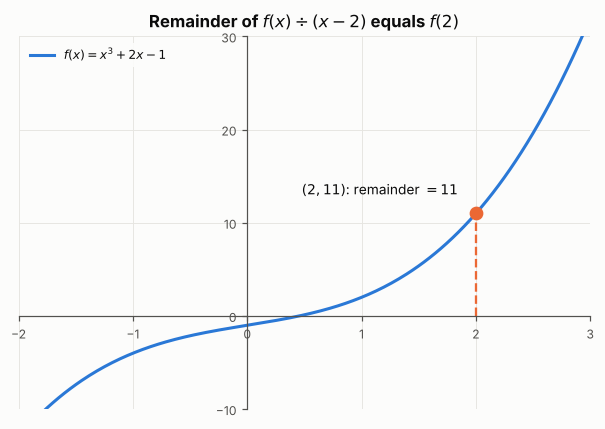

In [7]:
fig, ax = plt.subplots(figsize=(5.6, 4.0))
setup(ax, (-2, 3), (-10, 30), r"Remainder of $f(x) \div (x - 2)$ equals $f(2)$", ticks=1); ax.set_aspect("auto")
ax.set_yticks(np.arange(-10, 31, 10))
x = np.linspace(-2, 3, 300); ax.plot(x, x**3 + 2*x - 1, color=BLUE, label="$f(x) = x^3 + 2x - 1$")
ax.plot([2, 2], [0, 11], color=ORANGE, lw=1.5, ls="--"); dot(ax, 2, 11, color=ORANGE)
ax.text(1.85, 13, "$(2, 11)$: remainder $= 11$", ha="right", fontsize=9)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Leaving out a $0$ placeholder for a missing power. Every degree from the top down needs a slot.
- Using $-3$ in synthetic division for $x - 3$. For $x - k$ you use $k$; for $x + 3$, use $k = -3$.
- Using synthetic division for a divisor like $x^2 + 1$ or $2x - 1$ without adjusting. It's built for $x - k$ only. (For $2x - 1$, divide by $x - \tfrac{1}{2}$, then divide the quotient by 2.)
- Subtracting only the first term in long division. The minus applies to the whole product.
:::

:::{tip} Where this shows up
Division is how you find slant asymptotes (§5.6) and it's the first step of partial fractions, an integration technique in Stewart. Synthetic division is also an efficient way to evaluate a polynomial (Horner's method), which is how software evaluates polynomials.
:::

(sec-5-5)=
## 5.5 Zeros of Polynomial Functions

### The theorems

| Theorem | Statement |
|---|---|
| Remainder Theorem | Dividing $f(x)$ by $x - k$ leaves remainder $f(k)$. |
| Factor Theorem | $k$ is a zero of $f$ $\iff$ $x - k$ is a factor of $f$. |
| Rational Zero Theorem | For integer coefficients, every rational zero has the form $\dfrac{p}{q}$, with $p$ a factor of the constant term and $q$ a factor of the leading coefficient. |
| Fundamental Theorem of Algebra | Every polynomial of degree $n \ge 1$ has at least one complex zero. |
| Linear Factorization | $f(x) = a_n(x - c_1)(x - c_2)\cdots(x - c_n)$ with complex $c_i$: exactly $n$ zeros counting multiplicity. |
| Complex Conjugate Theorem | With real coefficients, if $a + bi$ is a zero then so is $a - bi$. |
| Descartes' Rule of Signs | # positive real zeros = # sign changes in $f(x)$, or fewer by an even number. # negative real zeros: same, using $f(-x)$. |

### Finding all zeros

1. List rational candidates $\pm \dfrac{p}{q}$ (use Descartes or a quick graph to rule some out).
2. Test candidates with synthetic division until the remainder is $0$.
3. Factor the quotient (deflate) and repeat. Once it's quadratic, factor or use the quadratic formula.

**Worked example.** $f(x) = 2x^3 - 3x^2 - 11x + 6$.

- Candidates: $p \in \{1, 2, 3, 6\}$, $q \in \{1, 2\}$, so $\pm 1, \pm 2, \pm 3, \pm 6, \pm \tfrac{1}{2}, \pm \tfrac{3}{2}$.
- Descartes: signs of $f(x)$ are $+ - - +$, 2 changes, so 2 or 0 positive zeros. $f(-x) = -2x^3 - 3x^2 + 11x + 6$ has signs $- - + +$, 1 change, so exactly 1 negative zero.
- $k = 3$ gives remainder $0$ (the synthetic division in §5.4), and the quotient factors: zeros $3$, $\tfrac{1}{2}$, $-2$. That matches Descartes.

**Worked example (complex zeros).** $g(x) = x^3 - x^2 + 4x - 4 = x^2(x - 1) + 4(x - 1) = (x - 1)(x^2 + 4)$. Zeros: $1, 2i, -2i$. Only the real zero appears on the graph.

**Worked example (building a polynomial from zeros).** Real coefficients, degree 3, zeros $2$ and $1 + i$, and $f(0) = 8$. The conjugate $1 - i$ must also be a zero, so

$$
\begin{aligned}
\big(x - (1 + i)\big)\big(x - (1 - i)\big) &= \big((x - 1) - i\big)\big((x - 1) + i\big) = (x - 1)^2 + 1 = x^2 - 2x + 2 \\
f(x) &= a(x - 2)(x^2 - 2x + 2) \\
f(0) &= a(-2)(2) = -4a = 8 \implies a = -2 \\
f(x) &= -2(x - 2)(x^2 - 2x + 2)
\end{aligned}
$$

Grouping as $(x - 1) \mp i$ turns the conjugate pair into a difference of squares, so the $i$'s cancel right away.

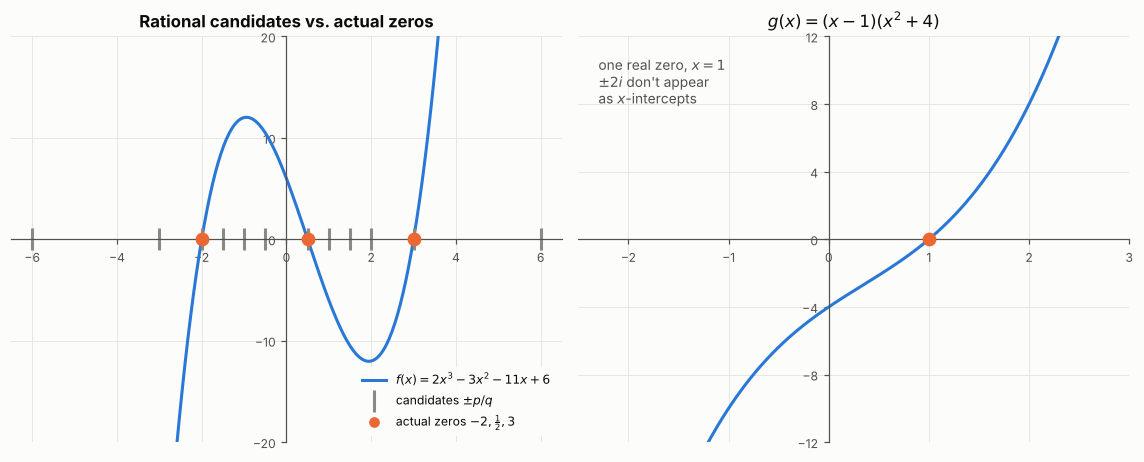

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
ax = axes[0]; setup(ax, (-6.5, 6.5), (-20, 20), "Rational candidates vs. actual zeros", ticks=1)
ax.set_aspect("auto"); ax.set_yticks(np.arange(-20, 21, 10)); ax.set_xticks(np.arange(-6, 7, 2))
x = np.linspace(-6.5, 6.5, 400); ax.plot(x, clip(2*x**3 - 3*x**2 - 11*x + 6, 21), color=BLUE,
                                         label="$f(x) = 2x^3 - 3x^2 - 11x + 6$")
cands = [1, 2, 3, 6, 0.5, 1.5]; cands = cands + [-c for c in cands]
ax.plot(cands, np.zeros(len(cands)), "|", ms=14, mew=2, color=GRAY, label="candidates $\\pm p/q$")
for z in (-2, 0.5, 3): dot(ax, z, 0, color=ORANGE)
ax.plot([], [], "o", color=ORANGE, label="actual zeros $-2, \\frac{1}{2}, 3$")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]; setup(ax, (-2.5, 3), (-12, 12), "$g(x) = (x - 1)(x^2 + 4)$", ticks=1)
ax.set_aspect("auto"); ax.set_yticks(np.arange(-12, 13, 4))
x = np.linspace(-2.5, 3, 300); ax.plot(x, clip((x - 1)*(x**2 + 4), 13), color=BLUE)
dot(ax, 1, 0, color=ORANGE)
ax.text(-2.3, 8, "one real zero, $x = 1$\n$\\pm 2i$ don't appear\nas $x$-intercepts", fontsize=9, color=INK2)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Listing $\dfrac{q}{p}$ instead of $\dfrac{p}{q}$. Constant term on top, leading coefficient on the bottom.
- Forgetting the $\pm$ on every candidate.
- After finding one zero, going back to test candidates on the original polynomial. Work with the quotient; it's smaller.
- Giving one complex zero without its conjugate.
:::

:::{important} The book underplays this
The Rational Zero Theorem only finds **rational** zeros. Most polynomials that come out of real problems have irrational zeros, and then you need the quadratic formula on a deflated quadratic or a numerical method. In Python, `np.roots([2, -3, -11, 6])` returns all zeros, real and complex.
:::

:::{tip} Where this shows up
Matrix eigenvalues are the zeros of a characteristic polynomial (Searle), and complex eigenvalue pairs in a population projection (Leslie) matrix signal oscillating age structure. The Fundamental Theorem of Algebra guarantees an $n \times n$ matrix has exactly $n$ eigenvalues counted with multiplicity.
:::

(sec-5-6)=
## 5.6 Rational Functions

A **rational function** is $f(x) = \dfrac{P(x)}{Q(x)}$ with polynomials $P$, $Q$, $Q \ne 0$. **Factor both first**, then:

| Feature | How to find it |
|---|---|
| Domain | all $x$ with $Q(x) \ne 0$ (use the **original** denominator) |
| Removable discontinuity (hole) | a factor cancels from top and bottom; the hole is at that $x$, with $y$ from the simplified function |
| Vertical asymptote | zeros of the denominator **after** cancelling |
| $x$-intercepts | zeros of the numerator after cancelling |
| $y$-intercept | $f(0)$, if $0$ is in the domain |

### Horizontal and slant asymptotes

Compare $\deg P = N$ with $\deg Q = D$:

| Degrees | End behavior |
|---|---|
| $N < D$ | horizontal asymptote $y = 0$ |
| $N = D$ | horizontal asymptote $y = \dfrac{\text{leading coeff. of } P}{\text{leading coeff. of } Q}$ |
| $N = D + 1$ | slant asymptote $y = q(x)$, the quotient from dividing $P$ by $Q$ |
| $N > D + 1$ | no horizontal or slant asymptote |

**Worked example.** $f(x) = \dfrac{x^2 - 1}{x^2 - 2x - 3} = \dfrac{(x - 1)(x + 1)}{(x - 3)(x + 1)}$.

- Domain: $x \ne 3, -1$. The $(x + 1)$ cancels, so $f(x) = \dfrac{x - 1}{x - 3}$ with a **hole** at $x = -1$, $y = \dfrac{-2}{-4} = \dfrac{1}{2}$.
- Vertical asymptote $x = 3$. Horizontal asymptote $y = \dfrac{1}{1} = 1$.
- $x$-intercept $(1, 0)$; $y$-intercept $\left(0, \dfrac{1}{3}\right)$.

### Behavior near a vertical asymptote

| Factor in the denominator | Near $x = a$ |
|---|---|
| $(x - a)^{\text{odd}}$ | the two sides go in **opposite** directions ($\infty$ on one side, $-\infty$ on the other) |
| $(x - a)^{\text{even}}$ | both sides go in the **same** direction |

Arrow notation: "as $x \to 3^{+}$, $f(x) \to \infty$" means that as $x$ approaches 3 from the right, the outputs grow without bound.

### Graphing a rational function

1. Factor; record the domain and cancel any common factors (holes).
2. Find the intercepts, vertical asymptotes, and horizontal or slant asymptote.
3. Use the multiplicities (or a test point in each interval) to get the sign of $f$ between the zeros and asymptotes.
4. Sketch each piece, approaching the asymptotes.

**Worked example (from features).** Vertical asymptotes $x = -2$ and $x = 3$, an $x$-intercept at $1$, horizontal asymptote $y = 0$, and $y$-intercept $(0, 2)$.

$$
\begin{aligned}
f(x) &= \frac{a(x - 1)}{(x + 2)(x - 3)} \quad \text{(degree 1 over degree 2 gives } y = 0\text{)} \\
f(0) &= \frac{a(-1)}{(2)(-3)} = \frac{a}{6} = 2 \implies a = 12 \\
f(x) &= \frac{12(x - 1)}{(x + 2)(x - 3)}
\end{aligned}
$$

**Worked example (slant).** $g(x) = \dfrac{x^2 + 1}{x - 1}$. Synthetic division by $x - 1$ gives $g(x) = x + 1 + \dfrac{2}{x - 1}$. Slant asymptote $y = x + 1$; vertical asymptote $x = 1$.

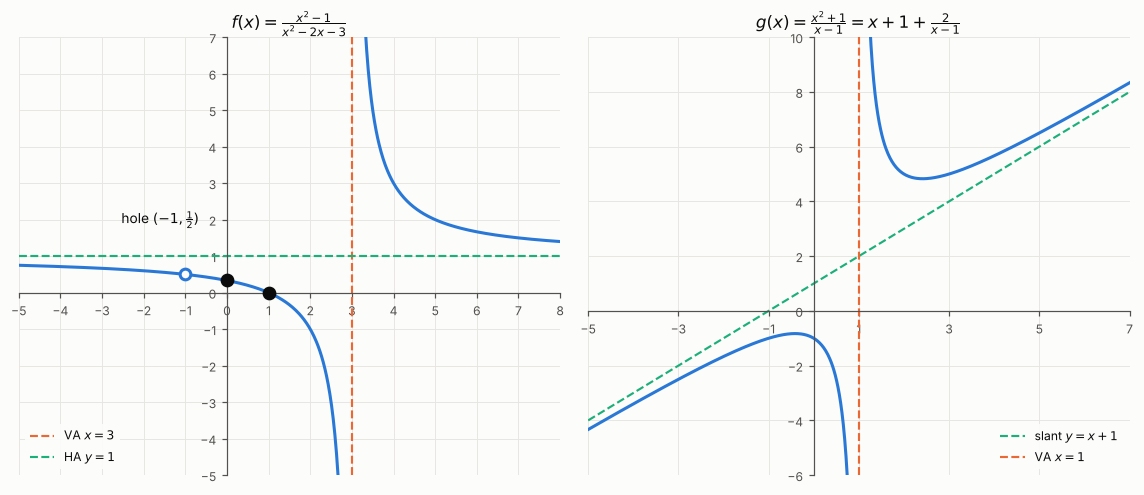

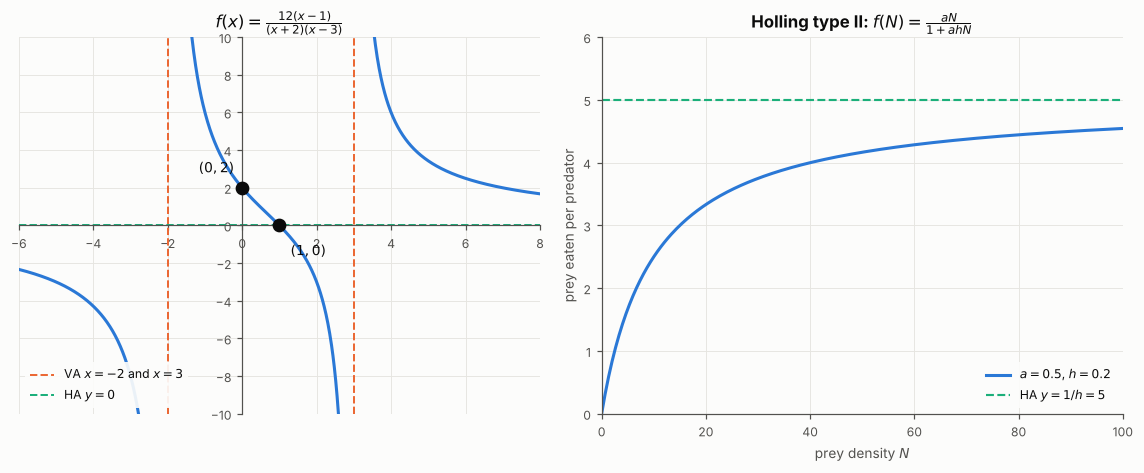

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
ax = axes[0]; setup(ax, (-5, 8), (-5, 7), r"$f(x) = \frac{x^2 - 1}{x^2 - 2x - 3}$"); ax.set_aspect("auto")
for lo, hi in [(-5, 2.97), (3.03, 8)]:
    x = np.linspace(lo, hi, 400); ax.plot(x, clip((x - 1)/(x - 3), 8), color=BLUE)
ax.axvline(3, color=ORANGE, ls="--", lw=1.4, label="VA $x = 3$")
ax.axhline(1, color=AQUA, ls="--", lw=1.4, label="HA $y = 1$")
dot(ax, -1, 0.5, filled=False); ax.text(-1.6, 1.9, "hole $(-1, \\frac{1}{2})$", ha="center", fontsize=9)
dot(ax, 1, 0, color=INK); dot(ax, 0, 1/3, color=INK)
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]; setup(ax, (-5, 7), (-6, 10), r"$g(x) = \frac{x^2 + 1}{x - 1} = x + 1 + \frac{2}{x - 1}$", ticks=2); ax.set_aspect("auto")
for lo, hi in [(-5, 0.97), (1.03, 7)]:
    x = np.linspace(lo, hi, 400); ax.plot(x, clip((x**2 + 1)/(x - 1), 11), color=BLUE)
xx = np.linspace(-5, 7, 10)
ax.plot(xx, xx + 1, color=AQUA, ls="--", lw=1.4, label="slant $y = x + 1$")
ax.axvline(1, color=ORANGE, ls="--", lw=1.4, label="VA $x = 1$")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
ax = axes[0]; setup(ax, (-6, 8), (-10, 10), r"$f(x) = \frac{12(x - 1)}{(x + 2)(x - 3)}$", ticks=2); ax.set_aspect("auto")
for lo, hi in [(-6, -2.03), (-1.97, 2.97), (3.03, 8)]:
    x = np.linspace(lo, hi, 400); ax.plot(x, clip(12*(x - 1)/((x + 2)*(x - 3)), 11), color=BLUE)
ax.axvline(-2, color=ORANGE, ls="--", lw=1.3, label="VA $x = -2$ and $x = 3$"); ax.axvline(3, color=ORANGE, ls="--", lw=1.3)
ax.axhline(0, color=AQUA, ls="--", lw=1.3, label="HA $y = 0$")
dot(ax, 1, 0, color=INK); dot(ax, 0, 2, color=INK)
ax.text(-0.2, 2.8, "$(0, 2)$", ha="right", fontsize=9); ax.text(1.3, -1.6, "$(1, 0)$", fontsize=9)
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]; data_axes(ax, r"Holling type II: $f(N) = \frac{aN}{1 + ahN}$", "prey density $N$", "prey eaten per predator")
N = np.linspace(0, 100, 300); a, h = 0.5, 0.2
ax.plot(N, a*N/(1 + a*h*N), color=BLUE, label="$a = 0.5$, $h = 0.2$")
ax.axhline(1/h, color=AQUA, ls="--", lw=1.4, label="HA $y = 1/h = 5$")
ax.set_xlim(0, 100); ax.set_ylim(0, 6); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Finding vertical asymptotes before cancelling. A factor that cancels gives a hole, not an asymptote.
- Finding the domain after cancelling. The hole's $x$-value is still excluded.
- Believing a graph can never cross a horizontal asymptote. It can, at finite $x$; the asymptote only describes behavior as $x \to \pm\infty$. A graph never crosses a **vertical** asymptote.
- Comparing the wrong things for the horizontal asymptote. Use the **leading terms** of the numerator and denominator.
- Assuming the graph shoots up on both sides of every vertical asymptote. Check the multiplicity or test a point on each side.
:::

:::{tip} Where this shows up
The Holling type II functional response, $f(N) = \dfrac{aN}{1 + ahN}$, and Beverton–Holt recruitment, $R = \dfrac{\alpha S}{1 + \beta S}$, are rational functions. Their horizontal asymptotes ($\tfrac{1}{h}$ and $\tfrac{\alpha}{\beta}$) are the biological maximums: maximum feeding rate and maximum recruitment. The odds $\dfrac{p}{1 - p}$ has a vertical asymptote at $p = 1$.
:::

(sec-5-7)=
## 5.7 Inverses and Radical Functions

This applies §3.7 to polynomials and radicals. The process is the same: check one-to-one, solve for $x$, swap, and track domains.

| Function | One-to-one? | Inverse |
|---|---|---|
| $x^n$, $n$ odd | yes, on $\mathbb{R}$ | $\sqrt[n]{x}$, on $\mathbb{R}$ |
| $x^n$, $n$ even | no; restrict to $x \ge 0$ (or $x \le 0$) | $\sqrt[n]{x}$ (or $-\sqrt[n]{x}$), on $[0, \infty)$ |
| $a(x - h)^2 + k$ | no; restrict to $x \ge h$ or $x \le h$ | $h \pm \sqrt{\dfrac{x - k}{a}}$; sign matches the side kept |
| $\sqrt{x - h} + k$ | yes | $(x - k)^2 + h$, **only for $x \ge k$** |

**Worked example.** $f(x) = \sqrt{x - 4} + 2$, with domain $[4, \infty)$ and range $[2, \infty)$.

$$
\begin{aligned}
y - 2 &= \sqrt{x - 4} \\
(y - 2)^2 &= x - 4 \implies x = (y - 2)^2 + 4 \\
f^{-1}(x) &= (x - 2)^2 + 4, \quad x \ge 2
\end{aligned}
$$

Without the restriction $x \ge 2$, the formula would describe a whole parabola, which is not the inverse of $f$.

**Worked example (odd power).** $h(x) = x^3 + 2$ is one-to-one on $\mathbb{R}$: $h^{-1}(x) = \sqrt[3]{x - 2}$, with no restriction needed.

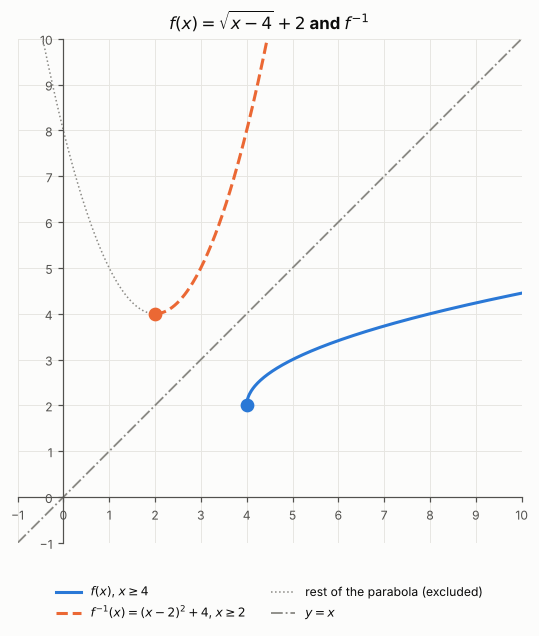

In [10]:
fig, ax = plt.subplots(figsize=(5.0, 6.0))
setup(ax, (-1, 10), (-1, 10), r"$f(x) = \sqrt{x - 4} + 2$ and $f^{-1}$")
x = np.linspace(4, 10, 300); ax.plot(x, np.sqrt(x - 4) + 2, color=BLUE, label=r"$f(x)$, $x \geq 4$")
xi = np.linspace(2, 10, 300); yi = (xi - 2)**2 + 4
ax.plot(xi, clip(yi, 10.5), color=ORANGE, ls="--", label=r"$f^{-1}(x) = (x - 2)^2 + 4$, $x \geq 2$")
xo = np.linspace(-1, 2, 100); ax.plot(xo, clip((xo - 2)**2 + 4, 10.5), color=GRAY, lw=1, ls=":",
                                      label="rest of the parabola (excluded)")
ax.plot([-1, 10], [-1, 10], color=GRAY, lw=1.2, ls="-.", label="$y = x$")
dot(ax, 4, 2, color=BLUE); dot(ax, 2, 4, color=ORANGE)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Squaring both sides and dropping the domain restriction on the inverse.
- Picking $+\sqrt{\ }$ when you kept the left half ($x \le h$) of a parabola. The sign must match.
- Squaring before isolating the radical: $(\sqrt{x - 4} + 2)^2 \ne (x - 4) + 4$.
:::

:::{tip} Where this shows up
Square-root and log transforms of count data (Ch. 6) are back-transformed with their inverses, and the domain restriction is why a back-transformed interval can't go negative. Allometric equations like $W = aL^b$ are inverted to get length from weight: $L = (W/a)^{1/b}$.
:::

(sec-5-8)=
## 5.8 Modeling Using Variation

| Phrase | Equation | Constant $k$ |
|---|---|---|
| $y$ varies directly with $x^n$ | $y = kx^n$ | $k = \dfrac{y}{x^n}$ (constant ratio) |
| $y$ varies inversely with $x^n$ | $y = \dfrac{k}{x^n}$ | $k = yx^n$ (constant product) |
| $y$ varies jointly with $x$ and $z$ | $y = kxz$ | $k = \dfrac{y}{xz}$ |

**Method:** translate to an equation with unknown $k$, use the one given data pair to find $k$, then answer the question.

**Worked example (direct).** $y$ varies directly with the cube of $x$, and $y = 24$ when $x = 2$. Then $24 = k \cdot 8$, so $k = 3$ and $y = 3x^3$. At $x = 3$: $y = 81$.

**Worked example (inverse).** Light intensity varies inversely with the square of distance. $I = 90$ at $d = 2$ m, so $k = 90 \cdot 4 = 360$ and $I = \dfrac{360}{d^2}$. At $d = 6$: $I = 10$. Tripling the distance cuts intensity by a factor of 9.

**Worked example (joint).** $z$ varies jointly with $x$ and the square of $y$, and $z = 54$ when $x = 2$, $y = 3$. Then $54 = k \cdot 2 \cdot 9$, so $k = 3$ and $z = 3xy^2$. At $x = 1$, $y = 4$: $z = 48$.

### Power laws are straight lines on log axes

Taking logs of $y = kx^n$ gives $\log y = \log k + n \log x$: a line with slope $n$ and intercept $\log k$. That's how an exponent like the $z$ in $S = cA^z$ gets estimated from data.

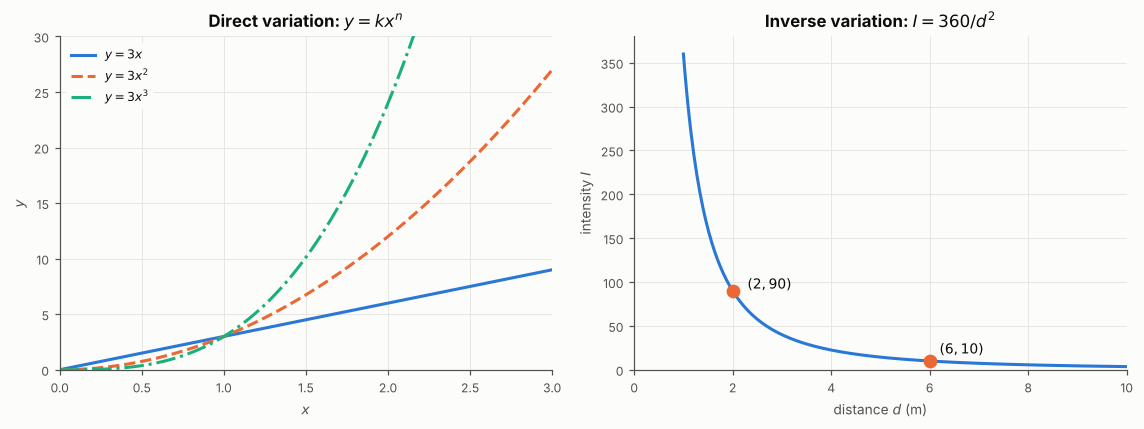

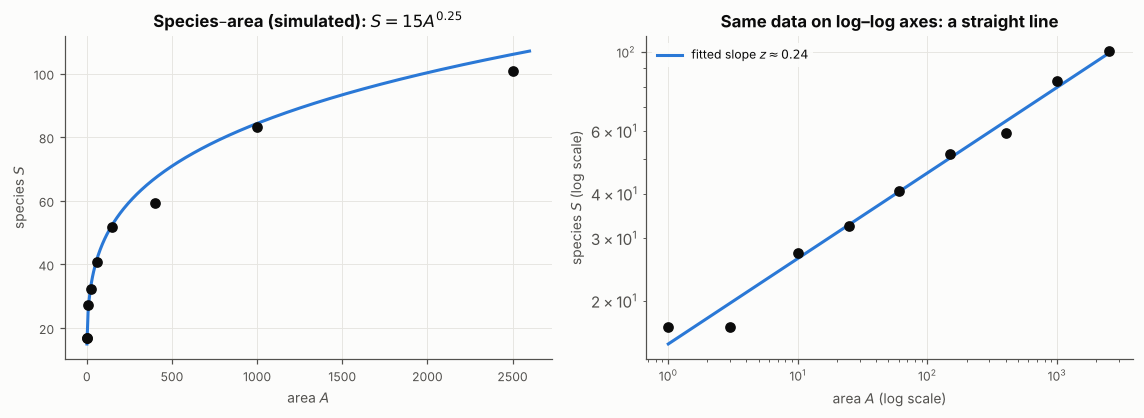

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
ax = axes[0]; data_axes(ax, "Direct variation: $y = kx^n$", "$x$", "$y$")
x = np.linspace(0, 3, 200)
ax.plot(x, 3*x, color=BLUE, label="$y = 3x$")
ax.plot(x, 3*x**2, color=ORANGE, ls="--", label="$y = 3x^2$")
ax.plot(x, 3*x**3, color=AQUA, ls="-.", label="$y = 3x^3$")
ax.set_xlim(0, 3); ax.set_ylim(0, 30); ax.legend(loc="upper left", fontsize=8)

ax = axes[1]; data_axes(ax, "Inverse variation: $I = 360/d^2$", "distance $d$ (m)", "intensity $I$")
d = np.linspace(1, 10, 300); ax.plot(d, 360/d**2, color=BLUE)
dot(ax, 2, 90, color=ORANGE); dot(ax, 6, 10, color=ORANGE)
ax.text(2.3, 92, "$(2, 90)$", fontsize=9); ax.text(6.2, 18, "$(6, 10)$", fontsize=9)
ax.set_xlim(0, 10); ax.set_ylim(0, 380)
plt.tight_layout(); plt.show()

rng = np.random.default_rng(3)
A = np.array([1, 3, 10, 25, 60, 150, 400, 1000, 2500.])      # simulated island areas
S = 15*A**0.25*np.exp(rng.normal(0, 0.06, A.size))          # S = c A^z, c = 15, z = 0.25
z_hat, logc_hat = np.polyfit(np.log10(A), np.log10(S), 1)
AA = np.linspace(1, 2600, 400)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
ax = axes[0]; data_axes(ax, "Species–area (simulated): $S = 15A^{0.25}$", "area $A$", "species $S$")
ax.plot(AA, 15*AA**0.25, color=BLUE); ax.plot(A, S, "o", ms=6, color=INK)
ax = axes[1]; data_axes(ax, "Same data on log–log axes: a straight line", "area $A$ (log scale)", "species $S$ (log scale)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.plot(AA, 10**logc_hat*AA**z_hat, color=BLUE, label=f"fitted slope $z \\approx {z_hat:.2f}$")
ax.plot(A, S, "o", ms=6, color=INK); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Writing $y = x^n + k$. Variation means $k$ **multiplies** (or divides), never adds.
- Missing the power: "varies with the square root of $x$" is $y = k\sqrt{x}$; "with the square of $d$" is $d^2$.
- Solving for $k$ and stopping. The question usually asks for a new value of $y$.
:::

:::{tip} Where this shows up
Power laws are everywhere in ecology: the species–area relationship $S = cA^z$, metabolic scaling $B \propto M^{3/4}$, and length–weight curves $W = aL^b$. Taking logs turns $y = kx^n$ into $\log y = \log k + n \log x$, a straight line you can fit with §4.3 regression. That's Chapter 6.
:::

## Exercises to prioritize

Odd numbers have answers in the back. This is the longest precalculus chapter; don't try to do every core problem in one sitting.

| Section | Core set | Notes |
|---|---|---|
| 5.1 | Algebraic 7–31 odd; Graphical 35–43 odd; Numeric 47, 49; Real-World 67–75 odd | Do the optimization problems. |
| 5.2 | Algebraic 7–29 odd; Graphical 31–43 odd; Numeric 47, 49 | Quick section. |
| 5.3 | Algebraic 7–39 odd; Graphical 41–65 odd; Real-World 75–79 odd | Graphical is the heart: zeros, multiplicity, writing formulas from graphs. |
| 5.4 | Algebraic 3–41 odd; Graphical 45–51 odd | Drill synthetic division until it's automatic; §5.5 depends on it. |
| 5.5 | Algebraic 7–43 odd; Graphical 45–53 odd (Descartes); Numeric 55–59 odd; Extensions 65–69 odd | |
| 5.6 | Algebraic 7–33 odd; Graphical 35–63 odd; Extensions 75–77; Real-World 79–83 odd | Second most important section. |
| 5.7 | Algebraic 5–19 odd; Graphical 31–39 odd; Real-World 55–63 odd | Lighter, since it repeats §3.7. |
| 5.8 | Algebraic 5–23 odd; Numeric 25–39 odd; Real-World 51–59 odd | |

**Cold diagnostic.** A few days after the section work, do the **Practice Test** (about 28 problems), timed and with no notes. The **Review Exercises** (1–48, grouped by section) are the follow-up.